# Serie I: estabilidad del ranking de variedades

Este análisis mide cuánto cambia el ranking económico completo cuando se remuestrean años. Responde la certeza de la recomendación de tres variedades del inciso I.1, con foco en la tercera posición. El análisis no estima una probabilidad real de superioridad ni observa cohortes de parcelas.

Se seleccionan 12 años completos con reemplazo por réplica; se conservan todas las localidades, variedades, cortes, etapas y repeticiones del año. Se usa YEAR original para contar años distintos en la regla de cobertura y la multiplicidad del sorteo para ponderar los promedios. Cada réplica vuelve a calcular diferencias frente a L01-299 en ambientes compartidos, reestima la media de referencia, aplica cobertura desde CROP 0 y elige la mejor duración para cada variedad elegible.

La población económica reproduce el notebook 03: STAGE=5, `T_SPACRE` y `TCA` completos, con filas `REQUIERE_REVISION=True` fuera del escenario base. `T_SPACRE` se trata como lb/acre; `TCA`, como ton/acre. La métrica es `[precio × azúcar esperada − 14 × caña esperada − 350 × cosechas − 1,100] / cosechas`, en US$/acre/año. Se examinan US$0.15, US$0.20 y US$0.25 por libra en el ranking ajustado; el ranking sin ajuste y la sensibilidad con filas marcadas se comparan a US$0.20.

Los percentiles y frecuencias describen remuestras de estos doce años bajo estas reglas. No son intervalos firmes ni probabilidades de que una variedad supere a otra en Louisiana o en Santa Ana.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().resolve()
if RAIZ.name == 'notebooks':
    RAIZ = RAIZ.parent
OUT = RAIZ / 'outputs' / 'serie1_ranking'
resumen = pd.read_csv(OUT / 'resumen_ranking.csv')
elegibilidad = pd.read_csv(OUT / 'elegibilidad_replicas.csv')
conteos = json.loads((OUT / 'conteos.json').read_text(encoding='utf-8'))
print(conteos)


{'filas_etapa5': 14092, 'filas_completas': 14033, 'filas_incluidas_escenario_principal': 14029, 'filas_fuera_stage5': 15311, 'filas_excluidas_por_faltantes': 59, 'filas_excluidas_por_revision': 4, 'filas_marcadas_solo_revision_en_completos': 4, 'anios': [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021], 'replicas': 500, 'semilla': 20261020, 'clones_universo_stage5': 40, 'ambientes_sin_referencia': 511}


## Posición y elegibilidad

La tabla separa la frecuencia top 3 entre réplicas donde la variedad fue elegible de la frecuencia sobre todas las réplicas. La diferencia entre ambas refleja cobertura insuficiente; una ausencia no equivale a un aporte igual a cero. Cuando una variedad nunca es elegible, su frecuencia condicional queda indefinida y la frecuencia sobre todas las réplicas es cero. El denominador por escenario también informa si hubo réplicas con menos de tres variedades elegibles.

In [2]:
principal = resumen.query("ESCENARIO == 'ajustado' and PRECIO_USD_LB == 0.20").sort_values('frecuencia_top3_sobre_todas_replicas', ascending=False)
display(principal[['CLONE','replicas_elegible','replicas_total','frecuencia_top3_condicional','frecuencia_top3_sobre_todas_replicas','rango_p05','rango_mediano','rango_p95','aporte_p05','aporte_mediano','aporte_p95','politica_moda','frecuencia_politica_moda','replicas_con_menos_de_tres']].head(12).round(3))


,CLONE,replicas_elegible,replicas_total,frecuencia_top3_condicional,frecuencia_top3_sobre_todas_replicas,rango_p05,rango_mediano,rango_p95,aporte_p05,aporte_mediano,aporte_p95,politica_moda,frecuencia_politica_moda,replicas_con_menos_de_tres
67,L01-299,500,500,1.000,1.000,1.0,2.0,3.0,569.180,631.983,691.157,4.0,1.000,0
47,HO12-615,438,500,0.957,0.838,1.0,3.0,3.0,568.639,619.286,675.923,4.0,0.824,0
58,HOCP09-804,499,500,0.543,0.542,2.0,3.0,6.0,548.423,598.633,662.240,4.0,0.986,0
62,HOCP14-885,202,500,1.000,0.404,1.0,1.0,1.0,666.322,725.099,788.768,3.0,1.000,0
66,L01-283,499,500,0.164,0.164,3.0,4.0,7.0,522.073,580.309,632.073,4.0,1.000,0
77,L99-226,466,500,0.047,0.044,4.0,6.5,9.0,499.754,559.974,613.898,4.0,0.976,0
72,L12-201,438,500,0.005,0.004,5.0,8.0,11.0,488.312,543.077,598.010,4.0,0.831,0
50,HO13-739,364,500,0.003,0.002,4.0,6.0,8.0,501.191,561.010,620.152,4.0,0.555,0
56,HOCP00-950,466,500,0.002,0.002,5.0,8.0,11.0,470.855,537.896,601.962,4.0,1.000,0
46,HO11-573,0,500,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


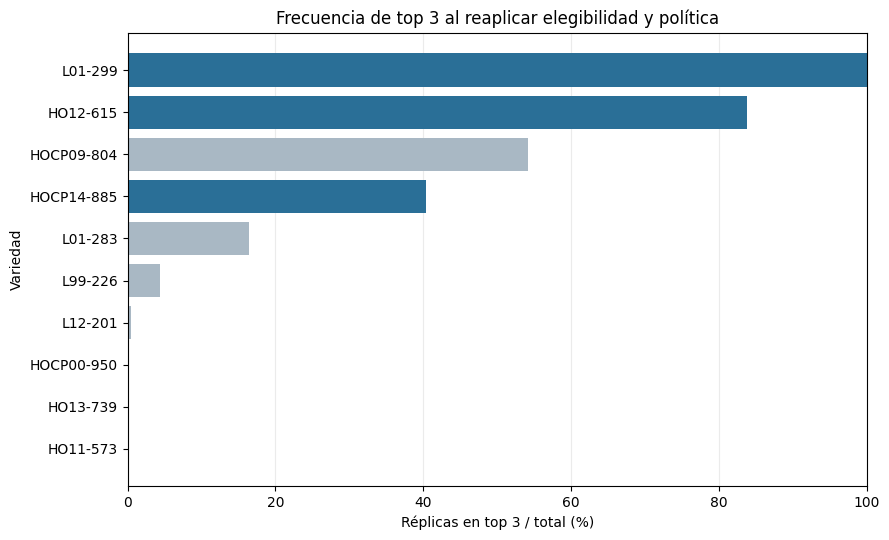

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.5))
plot = principal.head(10).sort_values('frecuencia_top3_sobre_todas_replicas')
ax.barh(plot.CLONE, 100*plot.frecuencia_top3_sobre_todas_replicas, color=['#2A6F97' if c in {'HOCP14-885','L01-299','HO12-615'} else '#A9B8C4' for c in plot.CLONE])
ax.set_xlabel('Réplicas en top 3 / total (%)')
ax.set_ylabel('Variedad')
ax.set_title('Frecuencia de top 3 al reaplicar elegibilidad y política')
ax.set_xlim(0,100); ax.grid(axis='x', alpha=.25); ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUT / 'frecuencia_top3.png', dpi=180, bbox_inches='tight')
plt.show()


## Candidata adicional: HOCP09-804

El ranking completo identifica alternativas que el top 3 original no mostraba. Esta comparación separa la frecuencia propia de HOCP09-804 de su comportamiento según la elegibilidad de HoCP14-885. Una frecuencia superior entre todas las variedades puede reflejar la falta de cobertura del competidor; por eso se presentan ambos denominadores y el aporte/rango cuando HOCP09-804 es elegible. La tabla también permite comparar su estabilidad con L01-283.

,replicas,HOCP09_elegible,HOCP09_top3,top3_condicional_HOCP09,rango_p05,rango_mediano,rango_p95,aporte_p05,aporte_mediano,aporte_p95
HOCP14-885,,,,,,,,,,
HoCP14-885 no elegible,298.0,297.0,264.0,0.889,1.0,3.0,4.0,548.182,604.838,668.636
HoCP14-885 elegible,202.0,202.0,7.0,0.035,4.0,4.0,6.0,548.491,591.920,650.794


,CLONE,replicas_elegible,replicas_total,frecuencia_top3_sobre_todas_replicas,rango_mediano,aporte_mediano,aporte_p05,aporte_p95
58,HOCP09-804,499,500,0.542,3.0,598.633,548.423,662.240
66,L01-283,499,500,0.164,4.0,580.309,522.073,632.073


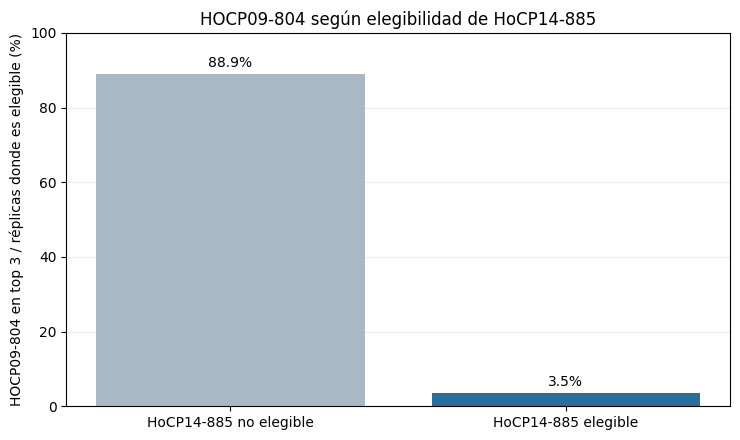

In [4]:
muestra_eleg = elegibilidad.query("ESCENARIO == 'ajustado' and PRECIO_USD_LB == 0.20")
estado = muestra_eleg.pivot(index='REPLICA', columns='CLONE', values='ELEGIBLE')
rank_h09 = pd.read_csv(OUT / 'ranking_replicas.csv').query("ESCENARIO == 'ajustado' and PRECIO_USD_LB == 0.20 and CLONE == 'HOCP09-804'").set_index('REPLICA')
condicional = estado[['HOCP14-885']].join(rank_h09[['RANGO','APORTE_ANUAL_USD_ACRE','COSECHAS_TOTALES']])
condicional['HOCP09_ELEGIBLE'] = estado['HOCP09-804']
resumen_cond = condicional.groupby('HOCP14-885').apply(lambda g: pd.Series({
    'replicas': len(g),
    'HOCP09_elegible': int(g.HOCP09_ELEGIBLE.sum()),
    'HOCP09_top3': int(g.RANGO.le(3).sum()),
    'top3_condicional_HOCP09': g.RANGO.le(3).sum()/g.HOCP09_ELEGIBLE.sum(),
    'rango_p05': g.RANGO.quantile(.05),
    'rango_mediano': g.RANGO.median(),
    'rango_p95': g.RANGO.quantile(.95),
    'aporte_p05': g.APORTE_ANUAL_USD_ACRE.quantile(.05),
    'aporte_mediano': g.APORTE_ANUAL_USD_ACRE.median(),
    'aporte_p95': g.APORTE_ANUAL_USD_ACRE.quantile(.95),
}), include_groups=False).rename(index={False:'HoCP14-885 no elegible',True:'HoCP14-885 elegible'})
display(resumen_cond.round(3))

comparacion = principal[principal.CLONE.isin(['HOCP09-804','L01-283'])][['CLONE','replicas_elegible','replicas_total','frecuencia_top3_sobre_todas_replicas','rango_mediano','aporte_mediano','aporte_p05','aporte_p95']]
display(comparacion.round(3))
fig, ax = plt.subplots(figsize=(7.5,4.5))
serie_cond = resumen_cond['top3_condicional_HOCP09']*100
ax.bar(serie_cond.index, serie_cond.values, color=['#A9B8C4','#2A6F97'])
ax.set_ylabel('HOCP09-804 en top 3 / réplicas donde es elegible (%)')
ax.set_title('HOCP09-804 según elegibilidad de HoCP14-885')
ax.set_ylim(0,100); ax.grid(axis='y',alpha=.25); ax.set_axisbelow(True)
for i, valor in enumerate(serie_cond.values): ax.text(i, valor+2, f'{valor:.1f}%', ha='center')
fig.tight_layout()
fig.savefig(OUT / 'alternativa_hocp09_condicional.png', dpi=180, bbox_inches='tight')
plt.show()

## Precio y ajuste ambiental

Un cambio de precio modifica el aporte y puede cambiar la duración económica óptima y el orden. La comparación sin ajuste muestra qué parte del tercer puesto depende del contraste aditivo con la referencia. La sensibilidad con filas marcadas mide cuánto pesa la exclusión de observaciones marcadas por calidad.

,ESCENARIO,PRECIO_USD_LB,CLONE,replicas_elegible,replicas_total,frecuencia_top3_condicional,frecuencia_top3_sobre_todas_replicas,rango_mediano,aporte_mediano,politica_moda,frecuencia_politica_moda,replicas_con_menos_de_tres
22,ajustado,0.15,HOCP14-885,202,500,1.000,0.404,1.0,249.150,3.0,1.000,0
27,ajustado,0.15,L01-299,500,500,1.000,1.000,2.0,208.151,4.0,1.000,0
7,ajustado,0.15,HO12-615,438,500,0.760,0.666,3.0,192.762,4.0,0.831,0
26,ajustado,0.15,L01-283,499,500,0.287,0.286,4.0,180.302,4.0,1.000,0
62,ajustado,0.20,HOCP14-885,202,500,1.000,0.404,1.0,725.099,3.0,1.000,0
67,ajustado,0.20,L01-299,500,500,1.000,1.000,2.0,631.983,4.0,1.000,0
47,ajustado,0.20,HO12-615,438,500,0.957,0.838,3.0,619.286,4.0,0.824,0
66,ajustado,0.20,L01-283,499,500,0.164,0.164,4.0,580.309,4.0,1.000,0
102,ajustado,0.25,HOCP14-885,202,500,1.000,0.404,1.0,1202.115,3.0,1.000,0
87,ajustado,0.25,HO12-615,438,500,0.979,0.858,2.0,1050.870,4.0,0.521,0


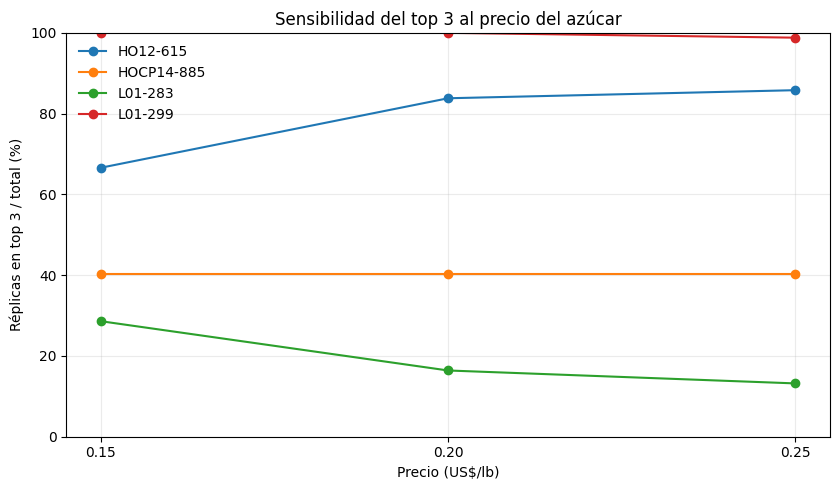

In [5]:
escenarios = resumen.query("(ESCENARIO == 'ajustado') or (PRECIO_USD_LB == 0.20)")
seleccion = escenarios[escenarios.CLONE.isin(['HOCP14-885','L01-299','HO12-615','L01-283'])]
display(seleccion[['ESCENARIO','PRECIO_USD_LB','CLONE','replicas_elegible','replicas_total','frecuencia_top3_condicional','frecuencia_top3_sobre_todas_replicas','rango_mediano','aporte_mediano','politica_moda','frecuencia_politica_moda','replicas_con_menos_de_tres']].sort_values(['ESCENARIO','PRECIO_USD_LB','rango_mediano']).round(3))

precios = resumen.query("ESCENARIO == 'ajustado' and CLONE in ['HOCP14-885','L01-299','HO12-615','L01-283']")
fig, ax = plt.subplots(figsize=(8.5, 5))
for clon, grupo in precios.groupby('CLONE'):
    grupo = grupo.sort_values('PRECIO_USD_LB')
    ax.plot(grupo.PRECIO_USD_LB, grupo.frecuencia_top3_sobre_todas_replicas*100, marker='o', label=clon)
ax.set_xlabel('Precio (US$/lb)'); ax.set_ylabel('Réplicas en top 3 / total (%)')
ax.set_title('Sensibilidad del top 3 al precio del azúcar'); ax.set_xticks([.15,.20,.25])
ax.set_ylim(0,100); ax.grid(alpha=.25); ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / 'sensibilidad_precio_top3.png', dpi=180, bbox_inches='tight')
plt.show()


## Lectura gerencial y límites

La decisión recomendada debe considerar el orden estimado, la probabilidad empírica de que cada variedad sea elegible bajo el remuestreo y su posición condicional cuando sí lo es. Con 12 años, la estabilidad es sensible a qué años aparecen; el precio solo escala el valor en algunos escenarios y puede modificar la duración elegida. La variedad de tercera opción debe tratarse como candidata condicionada al ajuste ambiental cuando L01-283 compita de cerca.

Este remuestreo no reproduce asignación aleatoria de tratamientos: cada año conserva los ambientes observados y la composición de variedades del archivo. No hay identificador de cohorte, parcela persistente ni causa de retiro; por eso el aporte es esperado bajo una política, no flujo realizado. La recomendación es una priorización para evaluar en Santa Ana con ensayos locales y registro de parcelas, no una tasa de expansión comprometida.